# 05 Développement de la solution

Ce notebook présente le modèle retenu pour prédire le prix de vente (`SalePrice`) des maisons d'Ames, ainsi que ses paramètres, ses hypothèses et les justifications de son choix. Il part des données préparées à l'[étape 4](04_pretraitement.ipynb)

**Modèle retenu : la moyenne de trois modèles** Lasso et Kernel Ridge sont des modèles linéaires; XGBoost est un modèle d'arbres de décision. Chaque modèle prédit le logarithme du prix; nous faisons la moyenne des trois prédictions, puis revenons en dollars.

**Évaluation.** Comme à l'étape 4, nous mesurons la RMSE des logarithmes des prix, la métrique de Kaggle, par validation croisée à cinq plis sur les 1 460 ventes de `train.csv` (`random_state=42`). Le prétraitement est réappris dans chaque pli, et les deux ventes aberrantes (524 et 1299) sont retirées de l'entraînement seulement.

**Plan.** La section 1 rappelle les approches essayées avant ce modèle. Les sections 2 à 4 justifient le choix : pourquoi combiner des modèles, pourquoi ces trois et ce que montrent les données. La section 5 présente le modèle, ses paramètres et ses hypothèses; la section 6, ses résultats et la soumission Kaggle.

## 1. Rappel de la version 1

### 1.1 Les approches essayées

Avant d'arriver à ce modèle, nous avons essayé trois approches (détails dans le [notebook 05, version 1](05_developpement_solution.ipynb) et dans `notebooks/experiences/`) :

1. **Un RAG** : retrouver cinq ventes comparables, puis demander à un grand modèle de langage d'estimer le prix. RMSE log de 0,133.
2. **XGBoost seul** : de 0,125 à 0,130, mieux que le RAG.
3. **La moyenne de cinq modèles** (Lasso, ElasticNet, Kernel Ridge, Gradient Boosting, XGBoost) : 0,123, mieux que les deux approches précédentes.

Ces trois scores sont mesurés sur les mêmes 292 maisons de validation.

La version 1 retenait donc la moyenne des cinq modèles. La sortie suivante reprend ses scores, mesurés cette fois par validation croisée à cinq plis (section 1.2), et compare les erreurs des cinq modèles.

1460 ventes étiquetées dans train.csv, 1459 maisons dans test.csv.


**1.1 Validation croisée des cinq modèles et de leur moyenne**

,RMSE log (moyenne des plis),Écart type entre plis
Moyenne des cinq (V1),0.1074,0.0081
Kernel Ridge,0.1100,0.0067
Lasso,0.1111,0.0069
ElasticNet,0.1112,0.0070
XGBoost,0.1132,0.0092
Gradient Boosting,0.1138,0.0102


**1.2 Corrélation des erreurs hors pli (log, ventes typiques)**

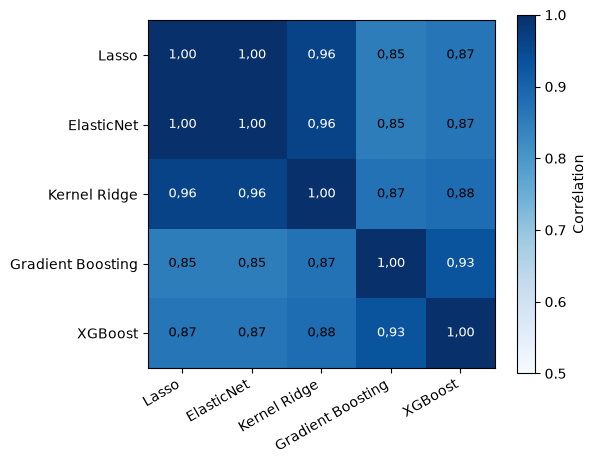

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.model_selection import KFold

from src.evaluation import cv_rmse
from src.preprocessing.steps.cleaning import unusual_sales
from src.training import (
    MEMBERS, RANDOM_STATE, cross_validate_model, fit_model, load_data, make_model,
)

def show_title(title):
    display(Markdown(f"**{title}**"))

# =======================================================================
# Chargement des données
# =======================================================================
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file())
X, y, test = load_data(root / "data/train.csv", root / "data/test.csv")
print(f"{len(X)} ventes étiquetées dans train.csv, {len(test)} maisons dans test.csv.")

# =======================================================================
# Validation croisée du modèle de la version 1 (moyenne des cinq modèles)
# =======================================================================
folds = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
oof, _ = cross_validate_model(make_model(list(MEMBERS)), X, y, folds)

show_title("1.1 Validation croisée des cinq modèles et de leur moyenne")
fold_scores = pd.DataFrame({
    name: [cv_rmse(y.iloc[v], oof[name].iloc[v], X.iloc[v]) for _, v in folds.split(X)]
    for name in oof
})
summary = pd.DataFrame({"RMSE log (moyenne des plis)": fold_scores.mean(),
                        "Écart type entre plis": fold_scores.std(ddof=0)})
summary = summary.rename(index={"Ensemble": "Moyenne des cinq (V1)"}).sort_values("RMSE log (moyenne des plis)")
display(summary.round(4))

show_title("1.2 Corrélation des erreurs hors pli (log, ventes typiques)")
errors = np.log(oof[list(MEMBERS)]).sub(np.log(y), axis=0)
correlation = errors[~unusual_sales(X, y)].corr()
figure, axis = plt.subplots(figsize=(6, 4.8))
image = axis.imshow(correlation, cmap="Blues", vmin=0.5, vmax=1)
axis.set_xticks(range(len(correlation)), correlation.columns, rotation=30, ha="right")
axis.set_yticks(range(len(correlation)), correlation.index)
for i in range(len(correlation)):
    for j in range(len(correlation)):
        value = correlation.iat[i, j]
        axis.text(j, i, f"{value:.2f}".replace(".", ","), ha="center", va="center",
                  color="white" if value > 0.9 else "black", fontsize=9)
figure.colorbar(image, ax=axis, label="Corrélation")
plt.tight_layout()
figure_path = root / "docs/figures/05_v1_correlation_erreurs_5_modeles.png"
figure_path.parent.mkdir(parents=True, exist_ok=True)
figure.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()

**Lecture.**
- **La moyenne des cinq modèles fait mieux que chaque modèle seul** : sa RMSE log est de 0,1074, contre 0,1100 pour Kernel Ridge, le meilleur modèle seul.
- **Les modèles forment deux groupes :**
  - **les modèles linéaires.** Lasso et ElasticNet sont deux régressions linéaires avec une pénalité. Ils fonctionnent presque de la même façon et se trompent exactement sur les mêmes maisons (1,00). Kernel Ridge est aussi une régression linéaire, mais il tient compte des interactions entre les variables, par exemple entre la qualité et la surface. C'est pourquoi ses erreurs ne sont pas tout à fait les mêmes (0,96);
  - **les modèles d'arbres.** Gradient Boosting et XGBoost construisent tous les deux une suite d'arbres de décision. Ils se trompent eux aussi sur des maisons semblables (0,93).
- **La moyenne gagne parce que les deux groupes se trompent sur des maisons différentes** (0,85 à 0,88 entre un modèle linéaire et un modèle d'arbres). Un modèle linéaire suppose que chaque caractéristique fait monter ou baisser le prix de façon régulière : plus de surface ou une meilleure qualité, prix plus élevé. Un modèle d'arbres sépare plutôt les maisons en groupes selon des seuils, par exemple les maisons de qualité 8 et plus d'un côté, les autres de l'autre. Comme ils ne lisent pas les données de la même façon, leurs erreurs se compensent en partie quand on fait la moyenne.

### 1.2 Pourquoi une validation croisée à cinq plis?

Nous n'avons que 1 460 ventes pour entraîner et évaluer le modèle. Si nous gardons 20 % des ventes pour l'évaluation, le score est mesuré sur environ 292 maisons seulement, et il dépend beaucoup des maisons tirées au hasard. Pour atténuer ce hasard, nous utilisons une validation croisée à cinq plis : les ventes sont réparties en cinq groupes d'environ 292 maisons, appelés plis, et chaque groupe sert à tour de rôle à l'évaluation.

| Tour | Groupe 1 | Groupe 2 | Groupe 3 | Groupe 4 | Groupe 5 |
|---|---|---|---|---|---|
| 1 | **Évaluation** | Entraînement | Entraînement | Entraînement | Entraînement |
| 2 | Entraînement | **Évaluation** | Entraînement | Entraînement | Entraînement |
| 3 | Entraînement | Entraînement | **Évaluation** | Entraînement | Entraînement |
| 4 | Entraînement | Entraînement | Entraînement | **Évaluation** | Entraînement |
| 5 | Entraînement | Entraînement | Entraînement | Entraînement | **Évaluation** |

À chaque tour, un nouveau modèle est entraîné sur quatre groupes (environ 1 168 ventes), puis évalué sur le groupe restant. Le score final est la moyenne des cinq scores. Cette méthode a trois avantages :
- **chaque vente est évaluée une fois**, par un modèle qui ne l'a pas vue pendant son entraînement. Ces prédictions servent aussi à comparer les erreurs des modèles (section 1.1) et à tester leurs combinaisons (section 4);
- **le score dépend moins du hasard** : dans la sortie de la section 1.1, le même ensemble obtient entre 0,100 et 0,123 selon le groupe évalué. Une seule partition n'aurait donné qu'un de ces chiffres;
- **aucune vente n'est perdue** : toutes servent à la fois à l'entraînement et à l'évaluation.

Les cinq modèles entraînés pendant la validation croisée servent seulement à mesurer l'erreur. Le modèle final est ensuite entraîné une seule fois sur toutes les ventes (section 6). La répartition en groupes est aléatoire, mais toujours la même d'une exécution à l'autre (`random_state=42`), pour que les résultats soient reproductibles.

## 2. Pourquoi combiner des modèles


### 2.1 Pourquoi la moyenne réduit l'erreur

Pour estimer le prix d'une maison, on peut demander l'avis de plusieurs évaluateurs plutôt que d'un seul. Chacun se trompe un peu, mais pas toujours dans le même sens ni sur les mêmes maisons. En faisant la moyenne de leurs avis, une partie de ces erreurs s'annule. Cette idée a une condition : les évaluateurs doivent avoir des façons de raisonner différentes. Deux évaluateurs qui utilisent exactement la même méthode font les mêmes erreurs, et la moyenne de leurs avis n'apporte rien. C'est le cas de Lasso et d'ElasticNet à la section 1.1.

Cette intuition se démontre. Le résultat suivant, appelé décomposition de l'ambiguïté (Krogh et Vedelsby, 1995), vaut pour toute moyenne de modèles de régression lorsque l'erreur est mesurée au carré, comme dans la RMSE. Pour chaque observation, ici chaque maison, l'erreur de la moyenne se décompose ainsi :

$$
\underbrace{(\bar{p} - y)^2}_{\text{erreur de la moyenne}}
= \underbrace{\frac{1}{k}\sum_{i=1}^{k} (p_i - y)^2}_{\text{erreur moyenne des modèles}}
- \underbrace{\frac{1}{k}\sum_{i=1}^{k} (p_i - \bar{p})^2}_{\text{désaccord entre les modèles}}
$$

où $y$ est le prix réel de la maison, $p_i$ le prix prédit par le modèle $i$, $\bar{p}$ la moyenne des prix prédits et $k$ le nombre de modèles. Nous l'appliquons au logarithme des prix, l'échelle de la métrique de Kaggle.

Autrement dit, **l'erreur de la moyenne est égale à l'erreur moyenne des modèles, moins leur désaccord.** Faire la moyenne retire donc à l'erreur exactement la valeur du désaccord. Comme le désaccord n'est jamais négatif, la moyenne se trompe toujours moins que les modèles en moyenne. À l'inverse, si les modèles prédisent tous la même chose, le désaccord est nul et la moyenne n'apporte rien.

Un modèle beaucoup moins bon que les autres modifie les deux termes de droite. Il augmente le désaccord, puisque ses prédictions s'écartent de celles des autres modèles, mais il augmente encore plus l'erreur moyenne des modèles. L'erreur de la moyenne peut alors devenir plus grande que celle des bons modèles pris seuls. Il vaut donc mieux combiner des modèles aussi bons les uns que les autres, mais qui se trompent sur des maisons différentes : le désaccord vient alors de vraies différences entre les modèles, et non d'un modèle qui se trompe beaucoup.

*Référence :* Krogh, A. et Vedelsby, J. (1995). « Neural Network Ensembles, Cross Validation, and Active Learning ». *Advances in Neural Information Processing Systems 7* (NIPS 1994), p. 231–238. [Lien](https://proceedings.neurips.cc/paper/1994/hash/b8c37e33defde51cf91e1e03e51657da-Abstract.html)

### 2.2 Les façons de combiner des modèles

Il existe plusieurs façons de combiner des modèles. Elles se divisent en deux groupes :
- **combiner des modèles différents**, déjà entraînés chacun de leur côté : moyenne simple, moyenne pondérée et empilement;
- **construire un ensemble à partir d'un seul type de modèle**, entraîné plusieurs fois : bagging et boosting.

Dans les exemples suivants, une maison est vendue 200 k$, et trois modèles prédisent respectivement 190 k$, 205 k$ et 215 k$.

#### Moyenne simple

Chaque modèle reçoit le même poids : on additionne les prédictions et on divise par le nombre de modèles. C'est la méthode la plus simple, car elle n'a aucun paramètre à apprendre. Elle suppose que les modèles sont à peu près aussi bons les uns que les autres.

**Exemple.** (190 + 205 + 215) / 3 = 203,3 k$. Chaque modèle compte pour un tiers.

#### Moyenne pondérée

Chaque modèle reçoit un poids différent, et les poids additionnés donnent 1. Un modèle plus fiable compte davantage. Les poids sont appris sur des données de validation, en cherchant ceux qui donnent la plus petite erreur. Avec peu de données, ces poids risquent toutefois de s'ajuster au hasard de l'échantillon plutôt qu'à une vraie différence de qualité entre les modèles.

**Exemple.** Avec des poids de 0,5, 0,3 et 0,2 : 0,5 × 190 + 0,3 × 205 + 0,2 × 215 = 199,5 k$. Le premier modèle compte ici pour la moitié de la prédiction.

#### Empilement (*stacking*)

Un second modèle, appelé méta-modèle, apprend comment combiner les prédictions des premiers. Il est entraîné sur les prédictions hors pli des modèles (section 1.2) et sur les vrais prix. Contrairement à la moyenne pondérée, il peut apprendre des règles plus fines, par exemple faire davantage confiance à un modèle pour les maisons chères et à un autre pour les maisons bon marché. C'est la méthode la plus souple, mais aussi la plus complexe et la plus exposée au surapprentissage.

**Exemple.** Le méta-modèle reçoit les trois prédictions (190, 205 et 215 k$) comme données d'entrée. S'il a appris que le troisième modèle est le plus fiable pour les grandes maisons, il peut prédire 212 k$ pour une grande maison, mais suivre davantage les deux autres modèles pour une petite.

#### Bagging

Le même type de modèle est entraîné plusieurs fois, chaque fois sur un échantillon différent des ventes. Chaque échantillon est tiré au hasard avec remise : certaines ventes y apparaissent plusieurs fois, d'autres pas du tout. On fait ensuite la moyenne des prédictions. Cette méthode stabilise les modèles très sensibles aux données d'entraînement, comme les arbres de décision : un arbre seul change beaucoup si on retire quelques ventes, mais la moyenne de plusieurs centaines d'arbres change peu.

**Exemple.** Une forêt aléatoire entraîne 500 arbres de décision, chacun sur un échantillon différent de ventes. Pour la maison de 200 k$, les arbres prédisent des prix variés, par exemple de 170 k$ à 230 k$, et la forêt renvoie leur moyenne.

#### Boosting

Les modèles sont entraînés l'un après l'autre, et chacun apprend à corriger les erreurs des précédents. La prédiction finale est la somme de toutes les corrections. Pour éviter de corriger trop vite, chaque correction est réduite par un taux d'apprentissage. Gradient Boosting et XGBoost fonctionnent ainsi : ce sont déjà des ensembles d'arbres. Notre configuration de XGBoost en compte 2 000.

**Exemple.** Un premier arbre prédit 180 k$. Il reste une erreur de 20 k$, et un deuxième arbre apprend à la corriger : il ajoute 12 k$, pour un total de 192 k$. Un troisième arbre corrige l'erreur restante de 8 k$, et ainsi de suite, jusqu'à s'approcher de 200 k$.

### 2.3 Notre choix : une moyenne simple sur le logarithme du prix

#### Une moyenne simple de trois modèles

Parmi les méthodes de la section 2.2, nous retenons la moyenne simple : le prix prédit est la moyenne des prédictions de Lasso, de Kernel Ridge et de XGBoost, avec le même poids pour chacun. C'est la méthode la plus simple, et elle convient à notre situation. Nos trois modèles obtiennent des scores proches : aucun ne mérite plus de poids que les autres. De plus, avec environ 1 160 ventes pour l'entraînement, des poids appris risqueraient de suivre le hasard de l'échantillon plutôt qu'une vraie différence entre les modèles.

#### Une moyenne sur le logarithme du prix

Les prix de vente sont asymétriques : la plupart des maisons se vendent autour de 160 k$, mais quelques-unes dépassent 500 k$ (étape 3). Plutôt que de travailler directement sur les prix, les modèles travaillent sur leur logarithme, dont la distribution est beaucoup plus régulière.

Le logarithme change aussi la façon de compter les erreurs : il mesure des écarts en pourcentage plutôt qu'en dollars. Une erreur de 10 k$ sur une maison de 100 k$ compte autant qu'une erreur de 50 k$ sur une maison de 500 k$, puisque les deux représentent 10 % du prix. Les maisons chères ne dominent donc plus le calcul de l'erreur. C'est aussi la façon dont Kaggle évalue les prédictions.

Nous faisons donc la moyenne des trois logarithmes prédits, puis nous revenons en dollars. La moyenne est ainsi calculée sur la même échelle que celle des modèles et de la métrique.

### 2.4 Ce que la combinaison ne corrige pas

#### Les erreurs communes à tous les modèles

La moyenne corrige seulement les erreurs sur lesquelles les modèles ne sont pas d'accord. Si tous les modèles se trompent de la même façon sur une maison, la moyenne se trompe aussi.

Cela arrive surtout quand une information importante manque dans les données, par exemple un intérieur rénové ou une vente faite sous le prix du marché. Aucun modèle ne voit cette information, donc la moyenne ne peut pas la corriger.

#### La qualité de chaque modèle reste essentielle

La moyenne ne peut pas faire beaucoup mieux que les modèles qui la composent. Elle réduit l'erreur moyenne des modèles d'une valeur égale à leur désaccord, mais elle part de cette erreur moyenne (section 2.1). Si les modèles sont tous faibles, leur moyenne restera faible, même s'ils sont en désaccord.

Combiner des modèles ne remplace donc ni un bon prétraitement des données (étape 4) ni un bon choix de modèles. La combinaison est une dernière amélioration, qui s'ajoute à des modèles déjà bons. C'est pourquoi la section 3 présente chacun des trois modèles retenus, ce qu'il capte dans nos données et pourquoi il est adapté à notre problème.

## 3. Les trois modèles retenus


Nous retenons trois modèles qui lisent les données de façons différentes. Lasso et Kernel Ridge appartiennent à la famille des modèles linéaires : ils supposent que le prix se construit en additionnant des effets. XGBoost appartient à la famille des arbres de décision : il découpe les maisons en groupes selon des seuils. Les trois obtiennent des scores proches (de 0,1100 à 0,1132 à la section 1.1), mais ils ne se trompent pas sur les mêmes maisons, ce qui est la condition pour que leur moyenne soit utile (section 2).

### 3.1 Lasso

**Principe.** Lasso est une régression linéaire : le logarithme du prix est prédit comme une somme pondérée des caractéristiques de la maison,

$$
\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_p x_p
$$

où chaque $x_j$ est une caractéristique (la surface, la qualité, l'âge…) et chaque $\beta_j$ est son coefficient, c'est-à-dire le poids qu'elle a dans le prix.

Les coefficients sont ceux qui rendent la fonction suivante la plus petite possible :

$$
\hat{\beta} = \arg\min_{\beta} \;
\underbrace{\frac{1}{2n} \sum_{i=1}^{n} \left( y_i - \hat{y}_i \right)^2}_{\text{erreur sur les ventes d'entraînement}}
+ \underbrace{\alpha \sum_{j=1}^{p} |\beta_j|}_{\text{pénalité sur les coefficients}}
$$

où $n$ est le nombre de ventes d'entraînement, $y_i$ le logarithme du prix réel de la vente $i$, $\hat{y}_i$ sa prédiction et $\alpha$ l'intensité de la pénalité.

Le premier terme est l'erreur du modèle sur les ventes d'entraînement. Le second est une pénalité qui augmente avec la taille des coefficients. En cherchant à rendre la somme des deux la plus petite possible, Lasso conserve seulement les caractéristiques vraiment utiles et met le coefficient des autres à zéro. Le paramètre $\alpha$ règle la force de cette pénalité : plus il est grand, plus Lasso retire de caractéristiques.

<p align="left">
  <img src="../docs/figures/03_1_lasso_coefficients.png" alt="Coefficients d'une régression linéaire ordinaire et de Lasso" width="900">
</p>

**Lecture de la figure.** Dans cet exemple à dix caractéristiques, la régression ordinaire attribue un coefficient à chacune d'elles, même à celles qui apportent peu. Lasso, lui, n'en conserve que cinq : il retire les caractéristiques selon leur utilité. Les salles de bain et les chambres en sont un exemple. La régression ordinaire leur donne un petit coefficient négatif, un résultat contre-intuitif qui s'explique par le fait qu'elles répètent une information déjà donnée par la surface habitable. Comme leur effet propre est faible, Lasso met leur coefficient à zéro.

**Adéquation à nos données.** Le prix d'une maison s'explique en grande partie par des effets qui s'additionnent : la qualité, la surface, l'âge et l'emplacement. Nos données contiennent toutefois beaucoup de colonnes, souvent liées entre elles, pour un nombre limité de ventes. Dans ce contexte, une régression ordinaire risque d'apprendre les particularités des ventes d'entraînement plutôt que les tendances générales du marché, en donnant du poids à de petits effets qui n'existent que par hasard dans l'échantillon. Grâce à sa pénalité, Lasso écarte ces petits effets et ne conserve que les caractéristiques qui expliquent vraiment le prix.

**Contribution à l'ensemble.** Lasso est le modèle le plus simple et le plus stable des trois. Il capte les grandes tendances du prix et peut les prolonger au-delà des ventes connues. Par exemple, pour une maison plus grande que toutes celles de l'entraînement, il prédit un prix plus élevé que tous ceux qu'il a vus, alors que XGBoost reste limité aux prix observés pendant l'entraînement (section 3.3).

**Limites.** Lasso suppose que chaque caractéristique a le même effet sur toutes les maisons. Par exemple, une salle de bain de plus ajoute le même pourcentage au prix d'une petite maison et d'une grande. Il ne tient pas compte des relations entre les caractéristiques, comme une surface qui vaut plus dans une maison de grande qualité, ni des effets de seuil. Kernel Ridge et XGBoost compensent ces limites.

### 3.2 Kernel Ridge

**Principe.** Kernel Ridge est une régression Ridge appliquée à des données enrichies. Il sert à capter les interactions entre les caractéristiques, c'est-à-dire les cas où l'effet d'une caractéristique dépend d'une autre : par exemple, un pied carré de plus peut valoir davantage dans une maison de grande qualité. Pour cela, le modèle ajoute aux caractéristiques de la maison leurs carrés et leurs produits deux à deux. Le logarithme du prix est alors prédit ainsi :

$$
\hat{y} =
\underbrace{\beta_0}_{\text{valeur de départ}}
+ \underbrace{\sum_{j} \beta_j x_j}_{\text{effet de chaque caractéristique}}
+ \underbrace{\sum_{j} \beta_{jj}\, x_j^2}_{\text{carrés}}
+ \underbrace{\sum_{j<k} \beta_{jk}\, x_j x_k}_{\text{interactions}}
$$

où chaque $x_j$ est une caractéristique de la maison et chaque $\beta$ est un coefficient appris pendant l'entraînement.

- $\beta_0$ est la valeur de départ de la prédiction, comme l'ordonnée à l'origine d'une droite. Les autres termes viennent l'augmenter ou la diminuer selon les caractéristiques de la maison.
- Le premier somme est la même que dans Lasso : chaque caractéristique, multipliée par son coefficient, ajoute un effet fixe au prix.
- Les carrés $x_j^2$ permettent à l'effet d'une caractéristique de changer selon sa propre valeur. Par exemple, un pied carré de plus peut rapporter moins dans une maison déjà très grande que dans une petite maison.
- Les produits $x_j x_k$ créent les interactions : ils permettent à l'effet d'une caractéristique de dépendre d'une autre.

Il reste à trouver la valeur de tous ces coefficients. Comme pour Lasso, le modèle cherche un compromis entre deux objectifs : bien prédire les ventes d'entraînement, et garder des coefficients petits pour ne pas s'ajuster au hasard de l'échantillon. Il choisit donc les coefficients qui rendent la fonction suivante la plus petite possible :

$$
\hat{\beta} = \arg\min_{\beta} \;
\underbrace{\sum_{i=1}^{n} \left( y_i - \hat{y}_i \right)^2}_{\text{erreur sur les ventes d'entraînement}}
+ \underbrace{\alpha \sum \beta^2}_{\text{pénalité sur les coefficients}}
$$

où $n$ est le nombre de ventes d'entraînement, $y_i$ le logarithme du prix réel de la vente $i$, $\hat{y}_i$ sa prédiction et $\alpha$ l'intensité de la pénalité.

Le premier terme est l'erreur du modèle sur les ventes d'entraînement, comme pour Lasso. La différence est dans la pénalité : Ridge pénalise le carré des coefficients plutôt que leur valeur absolue. Un petit coefficient ne coûte alors presque rien, si bien que Ridge réduit tous les coefficients sans en mettre aucun à zéro. Chaque interaction garde ainsi un petit poids, à moins que les données justifient un poids plus grand.

**Le noyau.** Avec nos 227 caractéristiques, les carrés et les produits deux à deux donneraient environ 26 000 colonnes, soit beaucoup plus que nos 1 460 ventes. Le noyau évite de construire ces colonnes.

Pour s'entraîner et prédire, Ridge n'a besoin que de comparer les maisons deux à deux, à l'aide de leur produit scalaire $x \cdot z = x_1 z_1 + x_2 z_2 + \dots + x_p z_p$. Un **noyau** est une fonction $K(x, z)$ qui donne directement le produit scalaire des données enrichies, à partir des caractéristiques d'origine seulement. On remplace donc $x \cdot z$ par $K(x, z)$, et le modèle travaille sur les données enrichies sans jamais les construire. C'est ce qu'on appelle l'astuce du noyau (*kernel trick*).

**Exemple de calcul.** Prenons deux maisons décrites par deux caractéristiques, $x = (2, 1)$ et $z = (1, 3)$, et le noyau $K(x, z) = (x \cdot z)^2$.

- *Sans le noyau*, on construit d'abord les produits deux à deux de chaque maison, $(x_1^2,\ x_1 x_2,\ x_2 x_1,\ x_2^2)$. On obtient $(4, 2, 2, 1)$ pour $x$ et $(1, 3, 3, 9)$ pour $z$, dont le produit scalaire vaut $4 \times 1 + 2 \times 3 + 2 \times 3 + 1 \times 9 = 25$.
- *Avec le noyau*, on calcule seulement $x \cdot z = 2 \times 1 + 1 \times 3 = 5$, puis $5^2 = 25$.

Le résultat est le même, mais le second calcul ne construit aucune nouvelle colonne. Avec nos 227 caractéristiques, l'écart devient important : d'un côté, environ 26 000 colonnes à construire pour chaque maison; de l'autre, 227 multiplications et un carré.

Notre modèle utilise le noyau $K(x, z) = (\gamma \, x \cdot z + c)^2$, où $\gamma$ et $c$ sont deux paramètres fixés à l'avance. En développant ce carré, on obtient $\gamma^2 (x \cdot z)^2 + 2c\gamma \, (x \cdot z) + c^2$. Le premier terme correspond aux produits deux à deux, le deuxième aux caractéristiques d'origine et le dernier à une constante : on retrouve les données enrichies décrites plus haut.

<p align="left"><img src="../docs/figures/03_2_kernel_ridge_interaction.png" alt="Prix prédit selon la surface et la qualité : modèle linéaire et Kernel Ridge" width="1000"></p>

**Lecture de la figure.** Dans cet exemple, les deux modèles sont entraînés sur deux caractéristiques seulement : la surface habitable et la qualité globale. On compare deux maisons de 1 500 pi², identiques sauf leur qualité : l'une est de qualité moyenne (5), l'autre de très bonne qualité (8). On ajoute ensuite 500 pi² à chacune et on mesure la hausse du prix prédit.

Le modèle linéaire donne la même hausse aux deux maisons : +14 %. Dans sa formule, la surface n'apparaît que dans un seul terme, $\beta_1 x_1$, qui ne dépend pas de la qualité. Agrandir une maison a donc le même effet, quelle que soit sa qualité.

Kernel Ridge donne une hausse de 11 % à la maison de qualité moyenne, mais de 18 % à celle de très bonne qualité. Comme les deux maisons ont la même surface, le carré de la surface joue de la même façon pour les deux. La différence vient du produit surface × qualité : grâce à ce terme, l'effet de la surface change avec la qualité. Selon ces ventes, agrandir une maison rapporte donc davantage quand elle est de meilleure qualité.

**Adéquation à nos données.** Le prix d'une maison s'explique en grande partie par des effets qui s'additionnent, ce qui explique les bons résultats des modèles linéaires. Parfois, toutefois, l'effet d'une caractéristique dépend d'une autre, comme la surface et la qualité dans la figure. Kernel Ridge peut capter ces relations sans qu'on ait à choisir à l'avance quelles paires de caractéristiques comptent. En contrepartie, il a beaucoup de coefficients à apprendre pour un nombre limité de ventes, et il risquerait d'apprendre les particularités des ventes d'entraînement plutôt que les tendances du marché. Sa pénalité limite ce risque : elle garde chaque coefficient petit, sauf si les données justifient un effet plus fort.

**Contribution à l'ensemble.** Kernel Ridge est le meilleur modèle seul de la version 1, avec une RMSE log de 0,1100 (section 1.1). Comme il appartient à la même famille que Lasso, leurs erreurs sont très liées (0,96). Il ne se trompe toutefois pas exactement sur les mêmes maisons, pour deux raisons : il tient compte des interactions, que Lasso ne voit pas, et il garde toutes les caractéristiques avec un petit poids, alors que Lasso en retire une partie.

**Limites.** Kernel Ridge est difficile à interpréter. Ses effets sont répartis entre des milliers de carrés et de produits, et le modèle ne calcule même jamais ces coefficients, puisqu'il ne construit pas les colonnes. On ne peut donc pas lire, comme avec Lasso, ce que vaut un pied carré ou un point de qualité.

Il est aussi sensible à l'échelle des colonnes. Comme le noyau multiplie les caractéristiques entre elles, une colonne aux grandes valeurs peut dominer toutes les autres. C'est pourquoi les colonnes sont standardisées à l'étape 4. Dans une de nos expériences (`notebooks/experiences/04_ensemble.ipynb`), une seule colonne mal mise à l'échelle avait suffi à faire passer son erreur de 0,11 à 0,17.

Enfin, il ne capte que les interactions entre deux caractéristiques, et ses effets restent réguliers : il ne repère pas les effets de seuil, comme un prix qui change brusquement à partir d'une certaine qualité. XGBoost compense cette limite (section 3.3). De plus, comme le modèle compare les ventes deux à deux, son calcul reste rapide avec nos 1 460 ventes, mais deviendrait lourd avec des centaines de milliers de ventes.

*Référence :* Saunders, C., Gammerman, A. et Vovk, V. (1998). « Ridge Regression Learning Algorithm in Dual Variables ». *Proceedings of the 15th International Conference on Machine Learning (ICML '98)*, p. 515–521.

### 3.3 XGBoost

**Principe.** XGBoost prédit le prix à l'aide d'arbres de décision. Un arbre pose une suite de questions par oui ou par non sur les caractéristiques de la maison, par exemple « la qualité est-elle d'au moins 7? » puis « la surface dépasse-t-elle 1 400 pi²? ». Chaque maison aboutit ainsi dans une feuille de l'arbre, qui lui attribue une valeur.

Pour bien apprendre, XGBoost construit plusieurs arbres, l'un après l'autre. Chaque nouvel arbre corrige l'erreur laissée par les arbres précédents : c'est ce qu'on appelle le boosting (section 2.2). Les arbres déjà construits ne sont jamais modifiés, et leurs corrections s'additionnent. Le logarithme du prix est prédit ainsi :

$$
\hat{y} =
\underbrace{f_0}_{\text{valeur de départ}}
+ \underbrace{\eta \sum_{t=1}^{T} f_t(x)}_{\text{corrections des arbres}}
$$

où $f_0$ est la même valeur de départ pour toutes les maisons, $f_t(x)$ la valeur de la feuille où tombe la maison $x$ dans l'arbre $t$, $T$ le nombre d'arbres et $\eta$ le taux d'apprentissage. Le taux d'apprentissage est un petit nombre qui réduit chaque correction : chaque arbre ne corrige qu'une partie de l'erreur. Le modèle avance ainsi à petits pas, ce qui lui évite de coller trop vite aux ventes d'entraînement, mais demande beaucoup d'arbres.

Pour construire chaque nouvel arbre, XGBoost calcule d'abord l'erreur qui reste pour chaque vente :

$$
r_i = y_i - \hat{y}_i^{(t-1)}
$$

où $y_i$ est le logarithme du prix réel de la vente $i$ et $\hat{y}_i^{(t-1)}$ sa prédiction par les arbres déjà construits. Par exemple, si une maison s'est vendue 200 k$ et que les arbres précédents prédisent 180 k$, il reste une erreur de 20 k$ à corriger (calculée en réalité sur le logarithme du prix). Le nouvel arbre $f_t$ est ensuite choisi pour rendre la fonction suivante la plus petite possible :

$$
f_t = \arg\min_{f} \;
\underbrace{\sum_{i=1}^{n} \left( r_i - f(x_i) \right)^2}_{\text{erreur sur l'écart à corriger}}
+ \underbrace{\lambda \sum_{j} w_j^2}_{\text{pénalité sur les feuilles}}
$$

où $w_j$ est la valeur de la feuille $j$ et $\lambda$ l'intensité de la pénalité.

Le premier terme montre que le nouvel arbre ne cherche pas à prédire le prix lui-même, mais l'erreur $r_i$ laissée par les arbres précédents. Le second terme limite la valeur des feuilles. Sans pénalité, une feuille donnerait la moyenne des erreurs de ses ventes. Avec la pénalité, on divise par le nombre de ventes plus $\lambda$, plutôt que par le nombre de ventes seul. Pour une feuille de plusieurs centaines de ventes, cet ajout ne change presque rien. Pour une feuille de quelques ventes seulement, il réduit nettement la correction. La pénalité freine donc surtout les petits groupes, dont la moyenne est peu fiable.

Enfin, chaque arbre est construit sur une partie seulement des données : XGBoost tire au hasard une partie des ventes et une partie des colonnes, et refait ce tirage pour chaque nouvel arbre. Ainsi, une vente inhabituelle ne pèse pas sur toutes les corrections. De même, une colonne très utile, comme la qualité, est absente de certains arbres, qui doivent alors apprendre avec d'autres colonnes, comme la surface ou le quartier. Le modèle tire ainsi son information d'un plus grand nombre de colonnes et dépend moins d'une seule d'entre elles.

<p align="left"><img src="../docs/figures/03_3_xgboost_arbres.png" alt="Les deux premiers arbres d'un XGBoost simplifié : chaque arbre corrige l'erreur qui reste" width="900"></p>

**Lecture de la figure.** Cet exemple simplifié montre les deux premiers arbres. Pour qu'ils restent lisibles, chaque arbre ne reçoit ici que deux colonnes sur quatre et ne pose que deux questions de suite. Dans notre modèle, le principe est le même, mais chaque arbre reçoit beaucoup plus de colonnes, tirées parmi toutes celles des données, et peut poser plus de questions. Le tirage des colonnes a été choisi pour l'exemple.

L'arbre 1 reçoit la qualité et la surface. Il sépare les ventes en quatre groupes selon ces deux colonnes : les maisons de qualité 7 ou moins et de petite surface se vendent en moyenne 27 % sous la prédiction de départ, alors que celles de qualité 8 et plus se vendent 76 % au-dessus. L'arbre n'ajoute toutefois qu'une petite partie de cet écart : −0,64 % pour le premier groupe et +1,13 % pour le dernier.

L'arbre 2 part ensuite de l'erreur qui reste après l'arbre 1. Comme il a reçu d'autres colonnes, le garage et l'année de construction, il pose d'autres questions et forme d'autres groupes. Il ajoute à son tour sa propre petite correction. Les écarts restent grands d'un arbre à l'autre, puisque chaque arbre n'en corrige qu'une petite partie. La prédiction finale est la somme de toutes ces corrections.

**Adéquation à nos données.** Nos données sont présentées en tableau : chaque vente est décrite par des surfaces, des scores de qualité, des années et des catégories. Sur ce type de données, les modèles d'arbres restent parmi les plus performants (Grinsztajn et al., 2022). Ils repèrent d'eux-mêmes les seuils, par exemple un prix qui augmente nettement à partir d'une certaine qualité. Ils combinent aussi les caractéristiques d'une question à l'autre, comme l'arbre 1 de la figure, qui interroge la qualité puis la surface. Tout cela se fait sans qu'on ait à préciser à l'avance la forme de la relation entre les caractéristiques et le prix. Enfin, comme un arbre ne fait que comparer des valeurs à des seuils, il ne dépend pas de l'échelle des colonnes.

**Contribution à l'ensemble.** Lasso et Kernel Ridge sont des modèles linéaires : ils lisent le prix comme une somme d'effets. XGBoost est le seul modèle de l'ensemble à lire les données autrement, comme une suite de seuils. Ses erreurs ressemblent donc moins à celles des deux autres : la corrélation entre les erreurs d'un modèle linéaire et celles d'un modèle d'arbres va de 0,85 à 0,88, contre 0,96 entre Lasso et Kernel Ridge (section 1.1). Même si son score seul est le moins bon des trois (0,1132), c'est donc lui qui devrait apporter le plus de désaccord, et donc le plus grand gain à la moyenne (section 2.1). La section 4 le vérifie sur les données.

**Limites.** XGBoost ne prolonge pas les tendances au-delà des maisons vues à l'entraînement. Dans chaque arbre, une maison plus grande que toutes les autres tombe dans la même feuille que les plus grandes maisons connues. Elle reçoit donc à peu près le même prix qu'elles, alors qu'un modèle linéaire comme Lasso prédirait un prix plus élevé (section 3.1). Pour la même raison, ses prédictions changent par paliers, à chaque seuil, plutôt que de façon régulière.

XGBoost demande aussi de régler plusieurs paramètres : le nombre d'arbres, leur profondeur, le taux d'apprentissage, et la part des ventes et des colonnes tirées pour chaque arbre. Un mauvais réglage peut lui faire apprendre les particularités des ventes d'entraînement, par exemple avec un taux d'apprentissage trop grand ou des arbres trop profonds.

Enfin, ses prédictions sont difficiles à expliquer. Un seul arbre se lit facilement, comme dans la figure, mais la prédiction finale additionne les corrections d'un très grand nombre d'arbres. On ne peut donc pas dire simplement ce que vaut un pied carré ou un point de qualité.

*Références :*
- Chen, T. et Guestrin, C. (2016). « XGBoost: A Scalable Tree Boosting System ». *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, p. 785–794.
- Grinsztajn, L., Oyallon, E. et Varoquaux, G. (2022). « Why Do Tree-Based Models Still Outperform Deep Learning on Typical Tabular Data? ». *Advances in Neural Information Processing Systems 35 (NeurIPS 2022)*.

### 3.4 Tableau comparatif

| | Lasso | Kernel Ridge | XGBoost |
|---|---|---|---|
| **Famille** | Linéaire | Linéaire, sur des données enrichies | Arbres de décision |
| **Comment il lit les données** | Une somme d'effets | Une somme d'effets, avec les carrés et les interactions deux à deux | Une suite de questions sur des seuils |
| **Caractéristiques utilisées** | Seulement les plus utiles | Toutes, avec leurs carrés et leurs produits | Une partie, tirée au hasard pour chaque arbre |
| **Pénalité** | Sur la valeur absolue des coefficients : en met certains à zéro | Sur le carré des coefficients : les réduit tous | Petits pas, pénalité sur les feuilles et tirage au hasard |
| **Point fort** | Simple, stable et facile à interpréter | Capte les interactions entre caractéristiques | Capte les seuils, sans supposer de forme |
| **Prolonge les tendances** | Oui | Oui | Non |
| **Sensible à l'échelle des colonnes** | Oui | Oui, fortement | Non |
| **Limite principale** | Ne voit ni les interactions ni les seuils | Difficile à interpréter; ne voit pas les seuils | Prédictions par paliers; plusieurs réglages; difficile à interpréter |
| **Score seul, RMSE log (section 1.1)** | 0,1111 | 0,1100 | 0,1132 |

Les trois modèles jouent des rôles différents. Lasso est le modèle de base : il garde seulement les caractéristiques importantes, et ses coefficients se lisent directement, ce qui en fait le modèle le plus simple et le plus stable des trois. Kernel Ridge part de la même idée, mais va beaucoup plus loin : il ajoute un très grand nombre d'interactions que Lasso ne voit pas. Il capte ainsi des effets plus fins, mais il a beaucoup plus de choses à apprendre avec le même nombre de ventes, et il est plus sensible à la préparation des données. Garder les deux équilibre la famille linéaire : Lasso apporte une base solide, et Kernel Ridge l'enrichit. XGBoost, enfin, ajoute les seuils qu'aucun des deux modèles linéaires ne repère, alors que les modèles linéaires prolongent les tendances là où XGBoost s'arrête. La section 4 vérifie que cette combinaison se traduit par une meilleure moyenne.

## 4. La preuve par les données

*À rédiger : tableau des moyennes de toutes les combinaisons des 5 modèles de la V1, calculées à partir des prédictions hors pli, sans réentraîner. Décision : pourquoi ces 3 modèles.*

In [3]:
# À compléter

## 5. Modèle retenu

*À rédiger : vue d'ensemble du modèle final.*

### 5.1 Schéma

*À rédiger : prétraitement make_base() → Lasso, Kernel Ridge, XGBoost → moyenne des log(prix) → prix prédit.*

### 5.2 Paramètres utilisés

*À rédiger : tableau des paramètres de chaque modèle, comment ils ont été choisis, seed utilisée.*

### 5.3 Hypothèses retenues

*À rédiger : hypothèses des données et hypothèse de chaque modèle.*

## 6. Résultats et entraînement final

*À rédiger : score de la V2 en validation croisée comparé à la V1, puis entraînement sur toutes les ventes et fichier de soumission Kaggle. Un seul bloc de texte de bilan.*

In [4]:
# À compléter

## Références

*À rédiger.*